In [63]:
import os
import cv2
import albumentations as A
from albumentations.pytorch import ToTensorV2
import numpy as np
import tqdm as tqdm
import matplotlib.pyplot as plt
import random

In [64]:
def visualize(image):
    plt.figure(figsize=(10,10))
    plt.axis('off')
    plt.imshow(image)

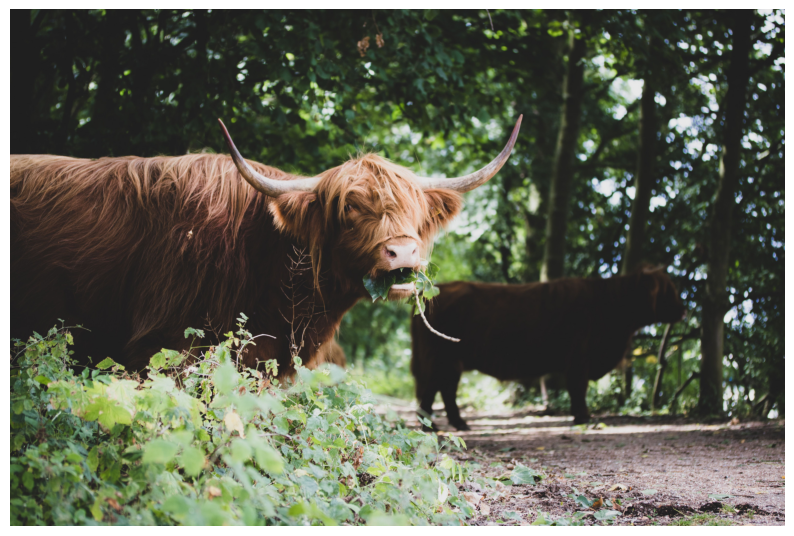

In [65]:
image = cv2.imread('/kaggle/input/datasets/msp689/sample-images-for-data-aug/pexels-annelies-brouw-976954-2863006.jpg')
image = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)
visualize(image)

### Few Image Transformation with Visualizations

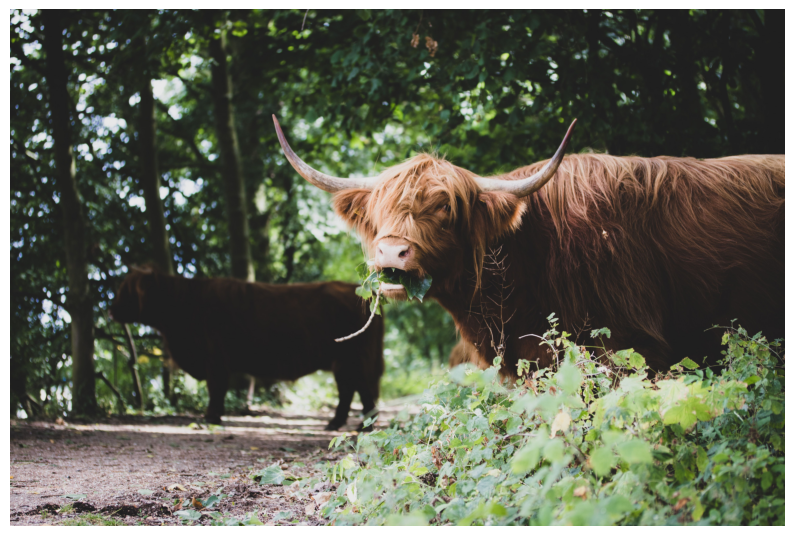

In [66]:
transform = A.HorizontalFlip(p=0.5)
random.seed(7)
augmented_image = transform(image=image)['image']
visualize(augmented_image)

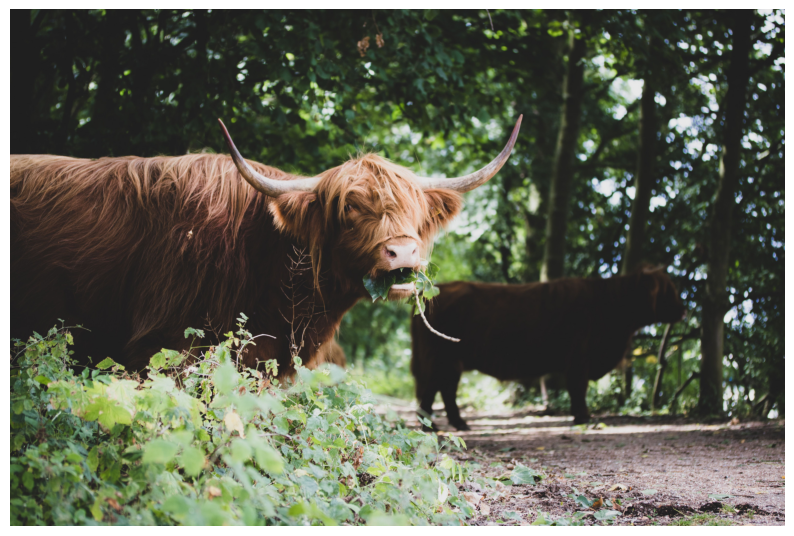

In [67]:
transform = A.ShiftScaleRotate(p=0.5)
random.seed(7)
augmented_image = transform(image=image)['image']
visualize(augmented_image)

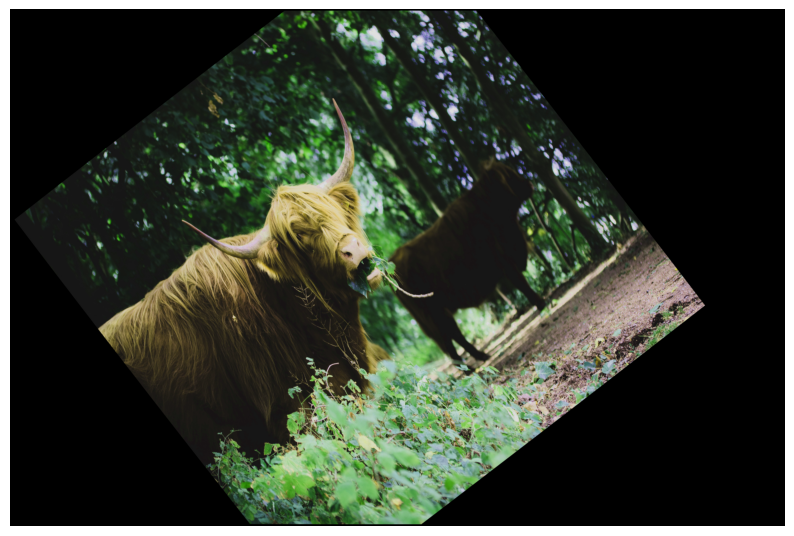

In [68]:
transform = A.Compose([
    A.CLAHE(),
    A.RandomRotate90(),
    A.Transpose(),
    A.ShiftScaleRotate(shift_limit=0.0625,scale_limit=0.50,rotate_limit=45,p=0.75),
    A.Blur(blur_limit=3),
    A.OpticalDistortion(),
    A.GridDistortion(),
    A.HueSaturationValue(),
])

random.seed(42)
augmented_image = transform(image=image)['image']
visualize(augmented_image)

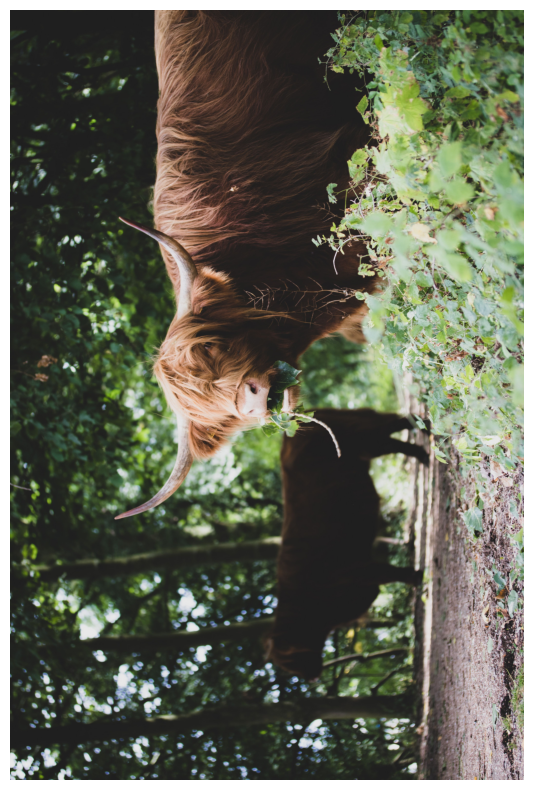

In [69]:
transform = A.Compose([
    A.RandomRotate90(),
    A.HorizontalFlip(),
    A.Transpose(),
    A.GaussNoise(),
    A.OneOf([
        A.MotionBlur(p=0.2),
        A.MedianBlur(blur_limit=3, p=0.1),
        A.Blur(blur_limit=3, p=0.1),
    ], p=0.2),
    A.ShiftScaleRotate(
        shift_limit=0.0625,
        scale_limit=0.2,
        rotate_limit=45,
        p=0.2
    ),
    A.OneOf([
        A.OpticalDistortion(p=0.3),
        A.GridDistortion(p=0.1),
    ], p=0.2),
    A.OneOf([
        A.CLAHE(clip_limit=2),
        A.RandomBrightnessContrast(),
    ], p=0.3),
    A.HueSaturationValue(p=0.3),
])

random.seed(42)

augmented_image = transform(image=image)['image']
visualize(augmented_image)

In [70]:
def create_augmentations():
    return A.Compose([
        A.HorizontalFlip(p=0.3),
        A.VerticalFlip(p=0.2),
        A.RandomRotate90(p=0.3),
        A.Transpose(p=0.2),
        ToTensorV2()
    ])

### Check out Documentation for albumentation and check more transformations

In [71]:
def augment_images(input_folder, output_folder, num_augmented_images=10):
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    image_files = [
        f for f in os.listdir(input_folder)
        if f.lower().endswith(('.png', '.jpg', '.jpeg'))
    ]

    augmenter = create_augmentations()

    for image_file in tqdm.tqdm(image_files, desc="Processing Images"):
        image_path = os.path.join(input_folder, image_file)

        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        base_name = os.path.splitext(image_file)[0]

        for i in range(num_augmented_images):
            augmented = augmenter(image=image)['image']
            augmented = augmented.permute(1, 2, 0).numpy()
            augmented = (augmented * 255).astype(np.uint8)

            output_path = os.path.join(
                output_folder, f"{base_name}_aug_{i}.jpg"
            )

            cv2.imwrite(
                output_path,
                cv2.cvtColor(augmented, cv2.COLOR_RGB2BGR)
            )

    print(f"Augmented images saved to {output_folder}")

In [72]:
input_folder = "/kaggle/input/datasets/msp689/sample-images-for-data-aug"
output_folder = "/kaggle/working/output"
num_augmentations_per_image = 10

augment_images(input_folder,output_folder,num_augmentations_per_image)

Processing Images: 100%|██████████| 6/6 [00:24<00:00,  4.01s/it]

Augmented images saved to /kaggle/working/output


In [ ]:
import shutil

# Folder containing your images
folder_path = "/kaggle/working/output"

# Create ZIP
shutil.make_archive(
    "/kaggle/working/output",
    "zip",
    folder_path
)

print("ZIP created successfully!")